# **Optimising a docking scoring function: normalisation, machine learning and benchmarks**

*Utrecht University Molecular Modelling courses from the [Bonvin lab](https://bonvinlab.org).*

This notebook continues **`Docking-scoring`** (part 1). There you rebuilt the **HADDOCK score** from its terms,
measured how well it ranks docking models, tried to beat it with your own weights and with a random search, and
saw that

* an improvement found on one set of models is easily **overfitting**: cross-validation kept a real gain for the
  rigid-body models of the case-study complex (IIA$^\text{Glc}$–HPr, PDB 1GGR), and none after refinement;
* weights tuned on that one complex did **not reliably transfer** to ten other complexes of a docking benchmark.

Here we ask whether we can do better by being smarter:

1. **Normalise** the terms before combining them (Exercise 1). Does it help, and how should it be done?
2. Replace the weighted sum by **machine learning**: regression, nearest neighbours, a random forest.
3. Optimise on **many complexes at once**, and test on a complex that was not used.

Throughout, what matters is the **top of the ranking**, not the correlation with model quality.

> **Solutions version — for instructors / checking only.** Every exercise is filled in with
> its worked solution and the solution blocks are unfolded, so all figures and numbers can be
> compared with the solution text. The student version is `Notebooks/Docking-scoring-optimisation.ipynb`.

---
## **1. What you need from part 1**

**The HADDOCK score** is a weighted sum of five terms, computed between the partners: van der Waals
($E_\text{vdW}$, `vdw`), electrostatics ($E_\text{elec}$, `elec`), desolvation ($E_\text{desolv}$, `desolv`), the
restraint violation energy ($E_\text{AIR}$, `air`), all in kcal/mol, and the buried surface area (BSA, `bsa`, Å²).
**Lower is better.** The weights for protein–protein docking:

| weight | rigid body | final refinement |
|---|---|---|
| $w_\text{vdW}$ | 0.01 | 1.0 |
| $w_\text{elec}$ | 1.0 | 0.2 |
| $w_\text{desolv}$ | 1.0 | 1.0 |
| $w_\text{AIR}$ | 0.01 | 0.1 |
| $w_\text{BSA}$ | −0.01 | 0 |

**Model quality** is measured by **DockQ** (0–1, higher is better), which defines the CAPRI classes:
incorrect (< 0.23), acceptable (0.23–0.49), medium (0.49–0.80) and high (≥ 0.80).

**Ranking quality.** $\text{RQ}_{10}$ is the mean DockQ of the top $N$ models, averaged over $N = 1 \ldots 10$: it
rewards putting the best models first. Over a set of complexes, the **success rate** at top $N$ is the fraction
of complexes with at least one model of a given class among their $N$ best-scored models.

**Cross-validation.** A scoring function must be judged on models — and complexes — it was not tuned on.

## **Showing and hiding the code**

The Python that only draws figures is a means to an end, so **those cells start collapsed**: you
see the figure, not the matplotlib that made it. Nothing is disabled — a collapsed cell runs
exactly like an open one. The cells you need to read or edit are left open.

* **One cell:** click the blue **collapser bar** just left of it (or *View → Collapse Selected Code*).
* **All of them:** *View → Collapse All Code* / *Expand All Code*.

---
## **2. Imports**

**numpy** and **matplotlib**, plus **scikit-learn** for the machine learning (installed in §6); the cell
installs what is missing, so the notebook also runs on Google Colab and in the browser (JupyterLite).

In [1]:
# --- Install required packages (works locally, on Colab, and on JupyterLite) ---
%pip install -q matplotlib numpy

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sys, warnings
if sys.platform == "emscripten":   # JupyterLite: its matplotlib build warns on every text label
    warnings.filterwarnings("ignore", message=r"The \w+ parameter as float was deprecated")
%matplotlib inline

# the five terms of the HADDOCK score, in a fixed order, and how to label them in figures
TERMS = ["vdw", "elec", "desolv", "air", "bsa"]
LABEL = {"vdw": "$E_\\mathrm{vdW}$ (kcal/mol)", "elec": "$E_\\mathrm{elec}$ (kcal/mol)",
         "desolv": "$E_\\mathrm{desolv}$ (kcal/mol)", "air": "$E_\\mathrm{AIR}$ (kcal/mol)",
         "bsa": "BSA (Å$^2$)", "score": "HADDOCK score", "dockq": "DockQ"}

# one fixed colour per CAPRI class (used in every figure)
CLASS_NAMES = ["incorrect", "acceptable", "medium", "high"]
CLASS_COLOR = ["#b9b9b9", "#eda100", "#2a78d6", "#1baf7a"]
C_RIGID, C_REF = "#eb6834", "#1c5cab"           # rigid-body / refined models
C_HADDOCK, C_YOU = "#4a4a4a", "#d55181"         # HADDOCK score / your score

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 1.6,
})


def works(f, *args):
    """True once f(*args) returns real numbers instead of the NaN placeholder."""
    try:
        return bool(np.all(np.isfinite(np.asarray(f(*args), dtype=float))))
    except Exception:
        return False

def show_wide(text):
    """Show printed text without wrapping long lines: a wide table gets a horizontal scroll bar."""
    from html import escape
    from IPython.display import display
    style = ("white-space: pre; overflow-x: auto; margin: 0 0 1em 0; line-height: 1.3; "
             "font-family: var(--jp-code-font-family, monospace); font-size: var(--jp-code-font-size, 13px);")
    display({"text/html": f'<pre style="{style}">{escape(text)}</pre>', "text/plain": text}, raw=True)


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: /Users/abonvin/haddock_git/haddock3/.venv-3.14/bin/python3.14 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


---
## **3. Data and tools from part 1**

The same data as in part 1, in the folder `scoring-data`: the case-study complex (1000 rigid-body and 200 refined
models) and the ten benchmark complexes. The two collapsed cells below read them and define the functions you
wrote or used in part 1 (`haddock_score`, `top_n`, `rank_quality`, `evaluate`, `print_table`, `random_search`,
`cross_validate`, `success_rate`, …), in their solved form. Open them if you want to look.

In [2]:
import urllib.request

FILES = {"pp_rigid":    "protein-protein-data-rigidbody.csv",       # the case-study complex, 1GGR
         "pp_refined":  "protein-protein-data-finalref.csv",
         "bm5_rigid":   "bm5-rigidbody.tsv",                        # ten benchmark complexes (section 7)
         "bm5_refined": "bm5-refined.tsv"}
URL = "https://raw.githubusercontent.com/haddocking/molmod-education/main/Notebooks/scoring-data/"

def find_data_dir():
    for d in (Path("scoring-data"), Path("Notebooks/scoring-data"), Path("../Notebooks/scoring-data")):
        if all((d / f).exists() for f in FILES.values()):
            return d
    d = Path("scoring-data")
    d.mkdir(exist_ok=True)
    for f in FILES.values():
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, d / f)
    return d

DATA_DIR = find_data_dir()
print("data folder:", DATA_DIR.resolve())


def load_models(path):
    """Read one data file -> dict {column name: numpy array}, one value per model."""
    text = Path(path).read_text(encoding="utf-8-sig")          # 'utf-8-sig' drops the BOM
    lines = [line for line in text.splitlines() if line.strip()]
    names = ["rank"] + lines[0].split(";")[1:]                   # column 1 is the rank
    rows = []
    for line in lines[1:]:
        fields = line.split(";")
        # every number has 3 decimals: "1.169.090" -> 1169090 / 1000 = 1169.09
        rows.append([int(field.replace(".", "")) / 1000 for field in fields[1:]])
    values = np.array(rows)
    data = {"rank": np.arange(1, len(rows) + 1)}
    for j, name in enumerate(names[1:]):
        data[name] = values[:, j]
    return data



def load_benchmark(path):
    """Read a benchmark file -> {complex: dict of arrays}, the models of each complex sorted by score."""
    lines = [line for line in Path(path).read_text().splitlines() if line.strip()]
    names = lines[0].split("\t")
    rows = [line.split("\t") for line in lines[1:]]
    out = {}
    for code in dict.fromkeys(row[0] for row in rows):         # the complexes, in file order
        sel = [row for row in rows if row[0] == code]
        d = {name: np.array([float(row[j]) for row in sel]) for j, name in enumerate(names) if j >= 2}
        order = np.argsort(d["score"], kind="stable")
        out[code] = {name: values[order] for name, values in d.items()}
    return out



DATA = {key: load_models(DATA_DIR / FILES[key]) for key in ("pp_rigid", "pp_refined")}
BM5 = {"rigid": load_benchmark(DATA_DIR / FILES["bm5_rigid"]),
       "refined": load_benchmark(DATA_DIR / FILES["bm5_refined"])}
COMPLEXES = list(BM5["refined"])
print("case study (1GGR):", {k: len(d["dockq"]) for k, d in DATA.items()}, "models")
print("benchmark:", len(COMPLEXES), "complexes:", " ".join(COMPLEXES))

data folder: /Users/abonvin/haddock_git/molmod-education/Notebooks/scoring-data
case study (1GGR): {'pp_rigid': 1000, 'pp_refined': 200} models
benchmark: 10 complexes: 1T6B 3WD5 2GAF 2AJF 3LVK 4LW4 5Y9J 3R9A 1HE8 1BGX


In [3]:
# ---------- tools from part 1 (Docking-scoring): the solved exercises and helper functions ----------

def class_of(dq):
    """CAPRI class of every model: 0 incorrect, 1 acceptable, 2 medium, 3 high."""
    dq = np.asarray(dq)
    return (dq >= 0.23).astype(int) + (dq >= 0.49) + (dq >= 0.80)


def class_histograms(d, keys, title, nbins=40):
    cls = class_of(d["dockq"])
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
    for ax, key in zip(axes.flat, keys):
        x = d[key]
        bins = np.linspace(x.min(), x.max(), nbins + 1)
        parts = [x[cls == c] for c in range(4)]
        ax.hist(parts, bins=bins, stacked=True, color=CLASS_COLOR,
                label=[f"{n} ({len(p)})" for n, p in zip(CLASS_NAMES, parts)])
        ax.set_xlabel(LABEL[key]); ax.set_ylabel("models")
        if key == "dockq":
            for t in (0.23, 0.49, 0.80):
                ax.axvline(t, color="k", lw=0.8, ls=":")
    axes.flat[0].legend(loc="upper right")
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()


def avg_ranks(x):
    """Rank of every element (0 = lowest); tied values share the average of their ranks."""
    x = np.asarray(x, dtype=float)
    order = np.argsort(x, kind="stable")
    r = np.empty(len(x)); r[order] = np.arange(len(x))
    _, inverse, counts = np.unique(x, return_inverse=True, return_counts=True)
    return (np.bincount(inverse, weights=r) / counts)[inverse]

def pearson(x, y):
    return np.corrcoef(x, y)[0, 1]

def spearman(x, y):
    """Spearman rank correlation = Pearson correlation of the ranks."""
    return np.corrcoef(avg_ranks(x), avg_ranks(y))[0, 1]


def terms_vs_dockq(d, keys, title):
    cls = class_of(d["dockq"])
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), sharey=True)
    for ax, key in zip(axes.flat, keys):
        ax.scatter(d[key], d["dockq"], s=7, c=[CLASS_COLOR[c] for c in cls], alpha=0.8, lw=0)
        for t in (0.23, 0.49, 0.80):
            ax.axhline(t, color="k", lw=0.6, ls=":")
        ax.set_xlabel(LABEL[key])
        ax.set_title(f"r = {pearson(d[key], d['dockq']):+.2f},   ρ = {spearman(d[key], d['dockq']):+.2f}")
    for ax in axes[:, 0]:
        ax.set_ylabel("DockQ")
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()


W_RIGID  = {"vdw": 0.01, "elec": 1.0, "desolv": 1.0, "air": 0.01, "bsa": -0.01}
W_REFINE = {"vdw": 1.0,  "elec": 0.2, "desolv": 1.0, "air": 0.1,  "bsa": 0.0}

def haddock_score(d, w):
    """HADDOCK score of every model in data set d (dict of arrays), with weights w (dict)."""
    total = 0
    for term in TERMS:
        total = total + w[term] * d[term]
    return total


def top_n(score, dockq, n):
    """DockQ of the n models with the lowest (best) score, best first."""
    order = np.argsort(score, kind="stable")
    return np.asarray(dockq)[order][:n]


def rank_quality(score, dockq, nmax=10):
    """RQ_nmax: the mean DockQ of the top N, averaged over N = 1 ... nmax (rank 1 counts most)."""
    ranked = top_n(score, dockq, nmax)
    return np.mean(np.cumsum(ranked) / np.arange(1, nmax + 1))


def evaluate(score, dockq):
    """Numbers that describe how well `score` ranks the models (lower score = better)."""
    ranked = top_n(score, dockq, len(dockq))
    best_class = lambda n: "-AMH"[class_of(ranked[:n]).max()]
    return {"r": pearson(score, dockq), "rho": spearman(score, dockq),
            "top1": ranked[0], "best5": ranked[:5].max(), "best10": ranked[:10].max(),
            "mean10": ranked[:10].mean(), "rq10": rank_quality(score, dockq),
            "class": best_class(1) + " " + best_class(5) + " " + best_class(10)}


def print_table(rows, title=""):
    """rows: list of (label, score array, dockq array)."""
    out = []
    if title:
        out.append(title)
    out.append(f"{'':32} {'r':>6} {'rho':>6} {'top1':>6} {'best5':>6} {'best10':>6} {'mean10':>7} {'RQ10':>6}"
               "   class top1/5/10")
    for label, s, dq in rows:
        e = evaluate(s, dq)
        out.append(f"{label:32} {e['r']:>+6.2f} {e['rho']:>+6.2f} {e['top1']:>6.3f} {e['best5']:>6.3f} "
                   f"{e['best10']:>6.3f} {e['mean10']:>7.3f} {e['rq10']:>6.3f}     {e['class']}")
    out.append("")
    show_wide("\n".join(out))


def topn_curves(ax, panels, nmax=50):
    """Top-N curves: mean DockQ of the top N (solid) and best DockQ within the top N (dashed)."""
    cols = [C_HADDOCK, C_YOU, C_REF, C_RIGID, "#1baf7a", "#eda100"]
    for (label, s, dq), col in zip(panels, cols):
        ranked = top_n(s, dq, nmax)
        n = np.arange(1, len(ranked) + 1)
        ax.plot(n, np.cumsum(ranked) / n, "-", color=col, label=f"ranked by {label}: mean DockQ of top N")
        ax.plot(n, np.maximum.accumulate(ranked), "--", color=col, lw=1, label=f"ranked by {label}: best DockQ in top N")
    for t in (0.23, 0.49, 0.80):
        ax.axhline(t, color="k", lw=0.6, ls=":")
    ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 20, 50]); ax.set_xticklabels([1, 2, 5, 10, 20, 50])
    ax.set_xlabel("N (number of top-ranked models)"); ax.set_ylabel("DockQ")
    ax.set_title("top-N curves: DockQ of the N best-scored models"); ax.legend(loc="lower left", fontsize=7)


def ranking_figure(panels, title):
    """panels: list of (label, score, dockq). Left: score vs DockQ (top 10 ringed); right: DockQ by rank."""
    fig, axes = plt.subplots(1, len(panels) + 1, figsize=(5.2 * (len(panels) + 1), 4.2))
    for ax, (label, s, dq) in zip(axes, panels):
        cls = class_of(dq)
        top = np.argsort(s, kind="stable")[:10]
        ax.scatter(s, dq, s=7, c=[CLASS_COLOR[c] for c in cls], alpha=0.8, lw=0)
        ax.scatter(s[top], dq[top], s=50, facecolors="none", edgecolors="k", lw=1, label="top 10")
        for t in (0.23, 0.49, 0.80):
            ax.axhline(t, color="k", lw=0.6, ls=":")
        ax.set_xlabel(label); ax.set_ylabel("DockQ"); ax.legend(loc="upper right")
    topn_curves(axes[-1], [(label, s, dq) for label, s, dq in panels])
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()


def random_search(d, start, n_trials=20000, seed=1, n=10, models=None):
    """Try n_trials random weight sets around `start`; return (best weights, their RQ_n).
       models: optional array of model indices to use (default: all models)."""
    rng = np.random.default_rng(seed)
    E = np.column_stack([d[t] for t in TERMS])                  # models x terms
    dockq = d["dockq"]
    if models is not None:
        E, dockq = E[models], dockq[models]
    w0 = np.array([start[t] for t in TERMS], dtype=float)
    sign = np.array([1, 1, 1, 1, -1.0])                         # BSA counts favourably
    scale = np.where(w0 != 0, w0, sign * 0.01 * np.abs(w0).max())   # a switched-off term can come back
    factor = 10 ** rng.uniform(-1.5, 1.5, size=(n_trials, len(TERMS)))
    off = rng.random((n_trials, len(TERMS))) < 0.15
    W = np.where(off, 0.0, scale * factor)
    W[0] = w0                                                   # trial 0 = the starting weights
    # RQ_n = sum over ranks k of c_k * DockQ(rank k), with c_k = (1/n) * sum_{N=k..n} 1/N
    c = np.cumsum((1 / np.arange(1, n + 1))[::-1])[::-1] / n
    quality = np.empty(n_trials)
    for i in range(0, n_trials, 2000):                         # in chunks, to limit memory use
        S = E @ W[i:i + 2000].T                                 # models x trials: all scores at once
        top = np.argpartition(S, n, axis=0)[:n]                 # the n best models of every trial ...
        top = np.take_along_axis(top, np.argsort(np.take_along_axis(S, top, 0), 0), 0)   # ... in order
        quality[i:i + 2000] = c @ dockq[top]
    best = int(np.argmax(quality))
    return dict(zip(TERMS, W[best])), quality[best]


def cross_validate(d, start, n_splits=10, n_trials=4000, seed=7):
    """Train on a random half, test on the other half; returns (HADDOCK, searched) test RQ10, per split."""
    rng = np.random.default_rng(seed)
    n_models = len(d["dockq"])
    result = []
    for split in range(n_splits):
        perm = rng.permutation(n_models)
        train, test = perm[: n_models // 2], perm[n_models // 2:]
        w, _ = random_search(d, start, n_trials=n_trials, seed=split, models=train)
        dq = d["dockq"][test]
        result.append((rank_quality(d["score"][test], dq), rank_quality(haddock_score(d, w)[test], dq)))
    return np.array(result)


def success_rate(ranked, n, threshold):
    """fraction of the complexes whose top n contains a model with DockQ >= threshold."""
    count = 0
    for dq in ranked:
        if np.max(dq[:n]) >= threshold:
            count = count + 1
    return count / len(ranked)


def benchmark_summary(scores, stage):
    """scores: {complex: score array} (lower = better). Returns (mean RQ10, success rates, RQ10 per complex)."""
    ranked = [top_n(scores[c], BM5[stage][c]["dockq"], len(scores[c])) for c in COMPLEXES]
    rq = np.array([rank_quality(scores[c], BM5[stage][c]["dockq"]) for c in COMPLEXES])
    rates = {(n, t): success_rate(ranked, n, t) for n in (1, 5, 10) for t in (0.23, 0.49)}
    return rq.mean(), rates, rq


def print_benchmark(rows, stage, title):
    """rows: list of (label, {complex: score array})."""
    out = []
    out.append(title)
    out.append(f"{'':34} {'mean':>6}   success rate (%) in top 1/5/10    RQ10 per complex")
    out.append(f"{'':34} {'RQ10':>6}   {'acceptable':>11} {'medium':>11}       " + " ".join(f"{c:>5}" for c in COMPLEXES)
               + "   vs HADDOCK (|diff| > 0.01)")
    ref = None
    for label, scores in rows:
        mean, rates, rq = benchmark_summary(scores, stage)
        acc = "/".join(f"{100 * rates[n, 0.23]:.0f}" for n in (1, 5, 10))
        med = "/".join(f"{100 * rates[n, 0.49]:.0f}" for n in (1, 5, 10))
        cmp = "" if ref is None else f"   better {np.sum(rq > ref + 0.01)}, worse {np.sum(rq < ref - 0.01)}"
        out.append(f"{label:34} {mean:>6.3f}   {acc:>11} {med:>11}       " + " ".join(f"{x:5.2f}" for x in rq) + cmp)
        if ref is None:
            ref = rq
    out.append("")
    show_wide("\n".join(out))


---
## **4. The starting point**

The random search and the cross-validation of part 1 (§9), repeated here because the rest of the notebook
builds on them: the best weights for the case-study complex at each stage (`BEST_W`), and their ranking quality
on test halves the search had not seen (`CV`).

In [4]:
def print_weights(name, start, w):
    """The weights found by the search next to the starting (HADDOCK) weights, and their ratio."""
    ratio = lambda t: (f"{'off':>9}" if w[t] == 0 else f"{'new':>9}" if start[t] == 0
                       else f"{w[t] / start[t]:>9.2g}")
    show_wide("\n".join([f"{name}: weights found by the random search",
                          f"   {'':16}" + "".join(f"{t:>9}" for t in TERMS),
                          f"   {'HADDOCK':16}" + "".join(f"{start[t]:>9.3g}" for t in TERMS),
                          f"   {'random search':16}" + "".join(f"{w[t]:>9.3g}" for t in TERMS),
                          f"   {'search / HADDOCK':16}" + "".join(ratio(t) for t in TERMS)]))


BEST_W, CV = {}, {}
for key, start, name in (("pp_rigid", W_RIGID, "rigid body"), ("pp_refined", W_REFINE, "refined")):
    d = DATA[key]
    BEST_W[key], _ = random_search(d, start)
    CV[key] = cross_validate(d, start)
    print_weights(name, start, BEST_W[key])
    print_table([("HADDOCK score", d["score"], d["dockq"]),
                 ("random search", haddock_score(d, BEST_W[key]), d["dockq"])])
    print(f"   cross-validated RQ10 (test halves): HADDOCK {CV[key][:, 0].mean():.3f}, searched "
          f"{CV[key][:, 1].mean():.3f}, better in {np.sum(CV[key][:, 1] > CV[key][:, 0])} of 10 splits\n")

rigid body: weights found by the random search
                         vdw     elec   desolv      air      bsa
   HADDOCK              0.01        1        1     0.01    -0.01
   random search      0.0202     4.76    0.236    0.227        0
   search / HADDOCK        2      4.8     0.24       23      off

r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score                     -0.56  -0.50  0.342  0.445  0.445   0.392  0.375     A A A
random search                     -0.21  -0.12  0.537  0.599  0.615   0.440  0.498     M M M

   cross-validated RQ10 (test halves): HADDOCK 0.397, searched 0.446, better in 9 of 10 splits



refined: weights found by the random search
                         vdw     elec   desolv      air      bsa
   HADDOCK                 1      0.2        1      0.1        0
   random search       0.633    0.205    0.643    0.116  -0.0949
   search / HADDOCK     0.63        1     0.64      1.2      new

r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score                     -0.27  -0.31  0.724  0.813  0.817   0.672  0.680     M H H
random search                     -0.16  -0.21  0.838  0.843  0.843   0.761  0.811     H H H

   cross-validated RQ10 (test halves): HADDOCK 0.676, searched 0.644, better in 3 of 10 splits



---
## **5. Exercise 1 — normalise the terms first?**

The terms of the score have very different **scales**: in the rigid-body set, $E_\text{elec}$ spans about
12 kcal/mol, $E_\text{AIR}$ about 750 kcal/mol and BSA about 900 Å². The size of a weight therefore says
little about how much a term *matters*. A common remedy is to **normalise** every term before combining
them. The usual choice is the **z-score**:

$$z \;=\; \frac{x - \bar x}{\sigma_x}$$

where $\bar x$ is the mean of the term over all models of the set and $\sigma_x$ its standard deviation.
After this, every term has mean 0 and standard deviation 1, and a weight of 1 means the same thing for
every term.

**(a)** Write `zscore(d)`: return a **copy** of the data set `d` in which every one of the five terms is
replaced by its z-score (the other columns — `score`, `dockq`, … — stay as they are).

The cells after the self-check then answer three questions: **what do the HADDOCK weights look like in
z units, does normalising let the search find better weights, and how good is the simplest possible
normalised score — all weights equal?**

In [5]:
# ---------- Exercise 1: complete the function ----------
def zscore(d):
    """(a) a copy of data set d in which every term in TERMS is replaced by its z-score."""
    z = dict(d)
    for term in TERMS:
        x = d[term]
        z[term] = (x - np.mean(x)) / np.std(x)
    return z

In [6]:
# ---------- self-check ----------
test_d = {"vdw": np.array([1.0, 2.0, 3.0]), "elec": np.array([-10.0, 0.0, 40.0]),
          "desolv": np.array([0.0, 0.0, 3.0]), "air": np.array([5.0, 6.0, 10.0]),
          "bsa": np.array([700.0, 800.0, 900.0]), "dockq": np.array([0.1, 0.5, 0.9])}
ex1_ok = False
try:
    z = zscore(test_d)
    means = np.array([np.mean(z[t]) for t in TERMS]); stds = np.array([np.std(z[t]) for t in TERMS])
    if z is test_d or any(z[t] is test_d[t] for t in TERMS) and np.allclose(stds, 1):
        print("    zscore() changed the original data: start with z = dict(d) and assign new arrays")
    elif all(np.allclose(z[t], test_d[t]) for t in TERMS):
        print("    not yet: the terms are not normalised")
    elif np.allclose(means, 0) and np.allclose(stds, 1):
        print(f"    every term now has mean 0 and standard deviation 1   OK")
        print(f"    vdw [1, 2, 3] -> {np.round(z['vdw'], 3)}")
        ex1_ok = np.allclose(z["dockq"], test_d["dockq"])
        if not ex1_ok:
            print("    ... but dockq was changed too: only normalise the five terms")
    elif np.allclose(stds, 1):
        print(f"    standard deviations are 1, but the means are {np.round(means, 3)}: subtract the mean first")
    elif np.allclose(means, 0):
        print(f"    means are 0, but the standard deviations are {np.round(stds, 3)}: "
              "divide by np.std(x) (not the variance, not the range)")
    else:
        print(f"    means {np.round(means, 3)}, std {np.round(stds, 3)}   <- expected 0 and 1")
except Exception as err:
    print("    not yet:", type(err).__name__, err)

    every term now has mean 0 and standard deviation 1   OK
    vdw [1, 2, 3] -> [-1.225  0.     1.225]


**What do the HADDOCK weights mean in z units?** A score $\sum w_t x_t$ ranks the models exactly like
$\sum (w_t\,\sigma_t)\, z_t$: the z-scores only shift and rescale each term, and shifting every score by
the same amount does not change their order. So $w_t\,\sigma_t$ is the **effective weight** of term $t$ —
how much it really moves the ranking. The figure shows it for both stages (as a fraction of the total).

rigid body: effective weight w*sigma  vdw +0.11  elec +2.21  desolv +6.27  air +1.36  bsa -1.51
   refined: effective weight w*sigma  vdw +8.39  elec +13.54  desolv +4.74  air +2.42  bsa +0.00


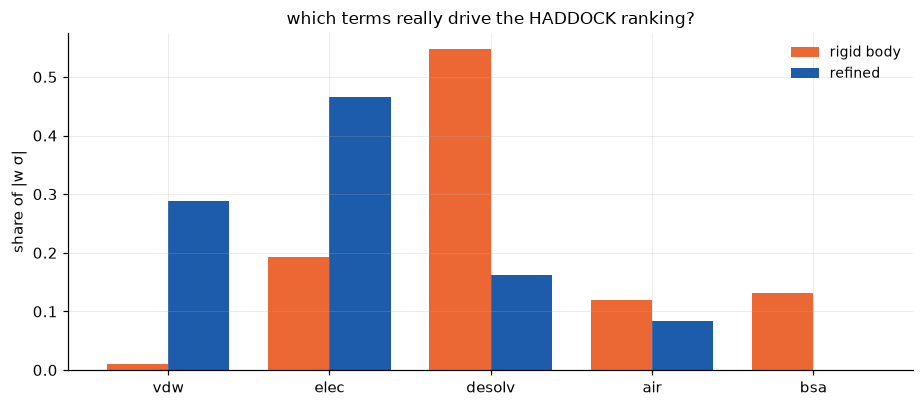

In [7]:
if not ex1_ok:
    print("Not yet: complete Exercise 1 first.")
else:
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    xs = np.arange(len(TERMS))
    for k, (key, w, col, name) in enumerate((("pp_rigid", W_RIGID, C_RIGID, "rigid body"),
                                             ("pp_refined", W_REFINE, C_REF, "refined"))):
        eff = np.array([w[t] * np.std(DATA[key][t]) for t in TERMS])
        frac = np.abs(eff) / np.abs(eff).sum()
        ax.bar(xs + (k - 0.5) * 0.38, frac, width=0.38, color=col, label=name)
        print(f"{name:>10}: effective weight w*sigma  " +
              "  ".join(f"{t} {e:+.2f}" for t, e in zip(TERMS, eff)))
    ax.set_xticks(xs); ax.set_xticklabels(TERMS)
    ax.set_ylabel("share of |w σ|"); ax.set_title("which terms really drive the HADDOCK ranking?")
    ax.legend()
    plt.tight_layout(); plt.show()

**Does normalising help the search?** Below, `random_search` is run on the **z-scored** terms, starting
from all weights equal (and −1 for BSA), and compared with the search on the raw terms of §4. Last, the
simplest normalised score of all: **every weight equal** (+1 for the four energies, −1 for BSA), with
nothing tuned.

In [8]:
EQUAL = {"vdw": 1.0, "elec": 1.0, "desolv": 1.0, "air": 1.0, "bsa": -1.0}

if not ex1_ok:
    print("Not yet: complete Exercise 1 first.")
else:
    BEST_WZ = {}
    for key, name in (("pp_rigid", "rigid body"), ("pp_refined", "refined")):
        d, dz = DATA[key], zscore(DATA[key])
        wz, _ = random_search(dz, EQUAL)
        BEST_WZ[key] = wz
        print(f"{name}: best z weights found  " + "  ".join(f"{t} {wz[t]:.3g}" for t in TERMS))
        print_table([("HADDOCK score", d["score"], d["dockq"]),
                     ("search on raw terms (sec. 4)", haddock_score(d, BEST_W[key]), d["dockq"]),
                     ("search on z-scored terms", haddock_score(dz, wz), d["dockq"]),
                     ("z-scored, all weights equal", haddock_score(dz, EQUAL), d["dockq"])])

rigid body: best z weights found  vdw 0  elec 0.0651  desolv 0  air 0.18  bsa 0


r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score                     -0.56  -0.50  0.342  0.445  0.445   0.392  0.375     A A A
search on raw terms (sec. 4)      -0.21  -0.12  0.537  0.599  0.615   0.440  0.498     M M M
search on z-scored terms          -0.19  -0.11  0.537  0.599  0.615   0.444  0.497     M M M
z-scored, all weights equal       -0.19  -0.16  0.342  0.367  0.477   0.313  0.290     A A A

refined: best z weights found  vdw 2.61  elec 9.58  desolv 2.7  air 3.17  bsa -11.5


r    rho   top1  best5 best10  mean10   RQ10   class top1/5/10
HADDOCK score                     -0.27  -0.31  0.724  0.813  0.817   0.672  0.680     M H H
search on raw terms (sec. 4)      -0.16  -0.21  0.838  0.843  0.843   0.761  0.811     H H H
search on z-scored terms          -0.17  -0.23  0.838  0.843  0.843   0.760  0.814     H H H
z-scored, all weights equal       -0.14  -0.19  0.813  0.843  0.843   0.759  0.799     H H H

One number for one set of models can be luck. The cell below repeats the comparison of the **equal-weight
z-score** with HADDOCK on 200 random halves of each set (normalising within each half).

In [9]:
def compare_on_halves(d, weights, n_halves=200, seed=3):
    """HADDOCK vs z-scored `weights` on random halves of d: returns array (n_halves, 4) of
       [HADDOCK RQ10, z RQ10, HADDOCK top1, z top1]."""
    rng = np.random.default_rng(seed)
    n_models = len(d["dockq"])
    out = []
    for _ in range(n_halves):
        half = rng.choice(n_models, n_models // 2, replace=False)
        sub = {k: v[half] for k, v in d.items()}
        s_z = haddock_score(zscore(sub), weights)
        out.append((rank_quality(sub["score"], sub["dockq"]), rank_quality(s_z, sub["dockq"]),
                    top_n(sub["score"], sub["dockq"], 1)[0], top_n(s_z, sub["dockq"], 1)[0]))
    return np.array(out)


if not ex1_ok:
    print("Not yet: complete Exercise 1 first.")
else:
    print(f"{'':12} {'RQ10 HADDOCK':>13} {'equal z':>8} {'z better':>9} {'top1 HADDOCK':>13} {'equal z':>8} {'z better':>9}")
    for key, name in (("pp_rigid", "rigid body"), ("pp_refined", "refined")):
        h = compare_on_halves(DATA[key], EQUAL)
        print(f"{name:12} {h[:, 0].mean():>13.3f} {h[:, 1].mean():>8.3f} {np.mean(h[:, 1] > h[:, 0]):>9.0%} "
              f"{h[:, 2].mean():>13.3f} {h[:, 3].mean():>8.3f} {np.mean(h[:, 3] > h[:, 2]):>9.0%}")

              RQ10 HADDOCK  equal z  z better  top1 HADDOCK  equal z  z better
rigid body           0.395    0.308        0%         0.365    0.316        1%
refined              0.683    0.709       71%         0.688    0.814       94%


**Questions**

**(b)** Which term dominates the HADDOCK ranking in the rigid-body stage, and which after refinement?
Does that agree with the size of the weights in the table of §1?

**(c)** Does the search on z-scored terms find a better scoring function than the search on raw terms?
Explain why (or why not) using the argument above the bar chart.

**(d)** How does the equal-weight z-score do at each stage, on the full set and on the random halves? What
might be the reason it fails for the rigid-body models?

**(e)** A z-score is computed from the **set of models** being ranked. What are the consequences? Think of:
a single model with a huge $E_\text{AIR}$; comparing the score of a model from one docking run with one from
another; a set in which all models are almost identical.

**(f)** So: does normalising help? What is it good for?

<details open>
<summary><b>Exercise 1 — worked solution</b></summary>

```python
def zscore(d):
    z = dict(d)
    for term in TERMS:
        x = d[term]
        z[term] = (x - np.mean(x)) / np.std(x)
    return z
```

**(b)** **Rigid body:** desolvation dominates ($w\sigma = 6.3$, more than half of the total), followed by
$E_\text{elec}$ (2.2), BSA (1.5) and $E_\text{AIR}$ (1.4); $E_\text{vdW}$ (0.1) hardly counts. **Refined:**
electrostatics dominates (13.5), then van der Waals (8.4), desolvation (4.7) and AIR (2.4). The raw weights
are misleading: after refinement $w_\text{elec} = 0.2$ is five times *smaller* than $w_\text{vdW}$, yet
$E_\text{elec}$ is the most important term, because its spread ($\sigma \approx 68$ kcal/mol) is so large.
Likewise $w_\text{AIR} = 0.01$ looks negligible in rigid body, but $\sigma_\text{AIR} \approx 136$ kcal/mol.

**(c)** No: the search on z-scored terms ends at the same $\text{RQ}_{10}$ as the search on raw terms
(0.497 vs 0.498 in rigid body, 0.814 vs 0.811 refined — the small differences are the luck of the random
search). Every z-weighted score ranks the models exactly like some raw-weighted score, so normalising cannot
reach rankings that were not reachable before. (Note that in z units the rigid-body optimum is simply
"electrostatics plus restraints": all other weights came out as 0.)

**(d)** **Rigid body: worse** ($\text{RQ}_{10}$ 0.290 against 0.375, and worse on every random half).
Equal weights give full importance to $E_\text{vdW}$, which in rigid body points the wrong way (clashes go
with good models). **Refined: better** — 0.799 against 0.680 on the full set, better in 71 % of the halves
(and the top-1 model better in 94 %). After refinement every term is meaningful and points the right way, so
giving each the same say is a reasonable, untuned choice. Equal weights only work when all terms are
informative — and even then, this is one complex.

**(e)** The z-score of a model depends on all the **other** models. One model with an extreme
$E_\text{AIR}$ inflates $\sigma_\text{AIR}$ and so shrinks the z-scores of all others (a more *robust*
alternative uses the median and the inter-quartile range instead of the mean and standard deviation —
or the ranks). A z-scored score has no absolute meaning: the same model gets a different score in a
different run, so z-scores can only be compared **within** one set. And if all models are nearly
identical, $\sigma$ is tiny and pure noise gets blown up to a spread of 1 — or $\sigma = 0$ and the
z-score is undefined.

**(f)** For **finding** the best weights for one set of models, normalising does not help: z-scoring is a
linear rescaling, so every z-weighted score is also a raw-weighted score with weights $w_t/\sigma_t$, and
the search reaches the same optimum. Normalising is useful for **reading** weights (it shows which terms
really drive the ranking, as in the bar chart), for **searching** (all weights on the same scale), and as a
parameter-free starting point. Its price is that the score becomes relative to the set of models.
</details>

---
## **6. Would machine learning do better?**

The HADDOCK score is a **weighted sum**: a linear function of its terms. Perhaps the relation between the
terms and model quality is not linear — a large buried surface may only be good when the restraints are
satisfied, for example. **Machine-learning** models can learn such relations from examples. Below, four
models learn to **predict DockQ** from the five terms (z-scored within each set of models, as in §5); the
models are then ranked by their predicted DockQ, highest first:

* **linear regression** — a weighted sum again, but with weights fitted (least squares) to reproduce the DockQ
  of every model, instead of searched for the best top of the list;
* **quadratic regression** — adds the squares and the pairwise products of the terms (20 inputs): a curved
  function, with interactions between terms;
* **k-nearest neighbours** — the predicted DockQ of a model is the mean DockQ of the 15 training models
  whose terms are most similar;
* **random forest** (from scikit-learn) — the average of 100 decision trees, each a cascade of
  yes/no questions such as "is $E_\text{AIR} < 40$?".

Note what they are trained for: to minimise the squared error of the predicted DockQ **over all models** —
not to put the best models on top.

Here they are tested **within the case-study complex**: trained on a random half of its models and tested
on the other half, as in part 1. The real test, on other complexes, follows in §7.

In [10]:
%pip install -q scikit-learn
from sklearn.ensemble import RandomForestRegressor


def features(d, models=None):
    """The five terms of the selected models as a (models x 5) array, z-scored within that selection."""
    X = np.column_stack([d[t] for t in TERMS])
    if models is not None:
        X = X[models]
    return (X - X.mean(axis=0)) / X.std(axis=0)

def quadratic(X):
    """The terms, their squares and their pairwise products."""
    cols = [X] + [X[:, [i]] * X[:, [j]] for i in range(X.shape[1]) for j in range(i, X.shape[1])]
    return np.hstack(cols)

def least_squares(X_train, y_train, X_test):
    A = np.column_stack([X_train, np.ones(len(X_train))])
    coef = np.linalg.lstsq(A, y_train, rcond=None)[0]
    return np.column_stack([X_test, np.ones(len(X_test))]) @ coef

def predict_dockq(method, X_train, y_train, X_test):
    """Train `method` on (X_train, y_train) and return its predicted DockQ for X_test."""
    if method == "linear regression":
        return least_squares(X_train, y_train, X_test)
    if method == "quadratic regression":
        return least_squares(quadratic(X_train), y_train, quadratic(X_test))
    if method == "k-nearest neighbours":
        dist = ((X_test[:, None, :] - X_train[None, :, :]) ** 2).sum(axis=-1)
        nearest = np.argsort(dist, axis=1)[:, :15]
        return y_train[nearest].mean(axis=1)
    if method == "random forest":
        forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=0)
        return forest.fit(X_train, y_train).predict(X_test)

METHODS = ["linear regression", "quadratic regression", "k-nearest neighbours", "random forest"]


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: /Users/abonvin/haddock_git/haddock3/.venv-3.14/bin/python3.14 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Ten random splits of each protein–protein set into a training and a test half.
For each method the table gives the ranking quality on the **training** half (models it has seen) and on the
**test** half, and in how many splits it beat the HADDOCK score on the test half. The weighted sum found by the
random search (§4, same splits) is included for comparison.

protein-protein, rigid body: RQ10 (mean over 10 splits)
                                 train   test   better than HADDOCK on test
   HADDOCK score                 0.395  0.397
   weighted sum (sec. 4 search)         0.446   9 of 10
   linear regression             0.448  0.458   10 of 10
   quadratic regression          0.522  0.521   10 of 10
   k-nearest neighbours          0.712  0.709   10 of 10
   random forest                 0.737  0.729   10 of 10
   DockQ correlation between a model and its nearest neighbour in term space: 0.78



protein-protein, refined: RQ10 (mean over 10 splits)
                                 train   test   better than HADDOCK on test
   HADDOCK score                 0.678  0.676
   weighted sum (sec. 4 search)         0.644   3 of 10
   linear regression             0.552  0.521   0 of 10
   quadratic regression          0.716  0.577   1 of 10
   k-nearest neighbours          0.675  0.648   3 of 10
   random forest                 0.780  0.623   2 of 10
   DockQ correlation between a model and its nearest neighbour in term space: 0.44



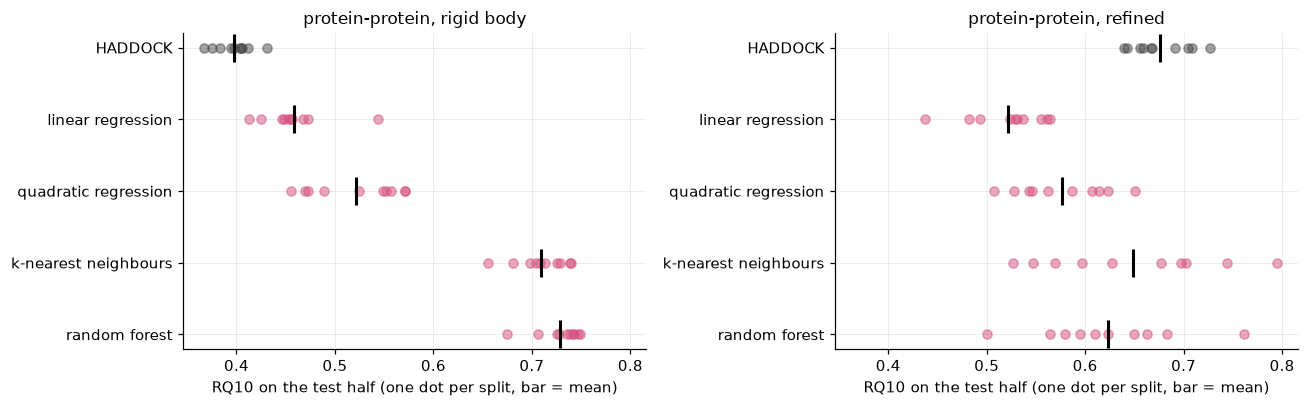

In [11]:
def ml_within(d, n_splits=10, seed=7):
    """RQ10 of every method on the training and test halves of n_splits random splits (same splits as cross_validate, sec. 4)."""
    rng = np.random.default_rng(seed)
    n_models = len(d["dockq"])
    res = {m: [] for m in ["HADDOCK"] + METHODS}
    for split in range(n_splits):
        perm = rng.permutation(n_models)
        train, test = perm[: n_models // 2], perm[n_models // 2:]
        X_tr, X_te = features(d, train), features(d, test)
        y_tr, y_te = d["dockq"][train], d["dockq"][test]
        res["HADDOCK"].append((rank_quality(d["score"][train], y_tr), rank_quality(d["score"][test], y_te)))
        for m in METHODS:
            pred_tr = predict_dockq(m, X_tr, y_tr, X_tr)
            pred_te = predict_dockq(m, X_tr, y_tr, X_te)
            # rank by predicted DockQ, highest first  ->  use minus the prediction as a "score"
            res[m].append((rank_quality(-pred_tr, y_tr), rank_quality(-pred_te, y_te)))
    return {m: np.array(v) for m, v in res.items()}


ML_A = {}
for key, name in (("pp_rigid", "rigid body"), ("pp_refined", "refined")):
    ML_A[key] = res = ml_within(DATA[key])
    h = res["HADDOCK"][:, 1]
    print(f"protein-protein, {name}: RQ10 (mean over 10 splits)")
    print(f"   {'':28} {'train':>6} {'test':>6}   better than HADDOCK on test")
    print(f"   {'HADDOCK score':28} {res['HADDOCK'][:, 0].mean():>6.3f} {h.mean():>6.3f}")
    if key in CV:
        print(f"   {'weighted sum (sec. 4 search)':28} {'':>6} {CV[key][:, 1].mean():>6.3f}   "
              f"{np.sum(CV[key][:, 1] > CV[key][:, 0])} of 10")
    for m in METHODS:
        print(f"   {m:28} {res[m][:, 0].mean():>6.3f} {res[m][:, 1].mean():>6.3f}   "
              f"{np.sum(res[m][:, 1] > h)} of 10")
    X = features(DATA[key])
    dist = ((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=-1)
    np.fill_diagonal(dist, np.inf)
    nn = dist.argmin(axis=1)
    print(f"   DockQ correlation between a model and its nearest neighbour in term space: "
          f"{pearson(DATA[key]['dockq'], DATA[key]['dockq'][nn]):.2f}\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, (key, name) in zip(axes, (("pp_rigid", "rigid body"), ("pp_refined", "refined"))):
    res = ML_A[key]
    labels = ["HADDOCK"] + METHODS
    for i, m in enumerate(labels):
        ax.plot(res[m][:, 1], np.full(len(res[m]), i), "o", color=C_HADDOCK if i == 0 else C_YOU, alpha=0.5)
        ax.plot(res[m][:, 1].mean(), i, "|", color="k", ms=18, mew=2)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.invert_yaxis()
    ax.set_xlabel("RQ10 on the test half (one dot per split, bar = mean)")
    ax.set_title(f"protein-protein, {name}")
plt.tight_layout(); plt.show()

**Questions**

**(a)** Which methods beat the HADDOCK score on the test halves, and at which stage? Compare their ranking
quality on the training and on the test halves: which methods overfit?

**(b)** In the rigid-body set, k-nearest neighbours and the random forest look spectacular. What have they
learnt? *(Hint: the nearest-neighbour correlation printed below each table.)* Would that help you in a real
docking run?

**(c)** The regressors were trained to predict the DockQ of **every** model. Is that what a scoring function
should do? What could you optimise instead?

<details open>
<summary><b>Section 6 — answers</b></summary>

**(a)** **Rigid body:** all four methods beat the HADDOCK score on the test halves in 10 of 10 splits —
linear regression 0.458, quadratic 0.521, k-nearest neighbours 0.709 and random forest 0.729, against 0.397
(and 0.446 for the searched weighted sum). Training and test values are almost equal: no classic
overfitting. **Refined:** none beats HADDOCK (0.676): linear 0.521, quadratic 0.577, k-nearest neighbours
0.648, forest 0.623. The quadratic regression (0.716 on training, 0.577 on test) and the forest (0.780 →
0.623) overfit: with 100 training models they learn noise.

**(b)** In rigid body, the DockQ of a model correlates at 0.78 with that of its **nearest neighbour** in
term space. Rigid-body docking produces families of nearly identical poses, with nearly identical energy
terms; a random split puts siblings of every family in both halves. The forest and k-nearest neighbours
simply learn "this corner of term space is where the correct pose of *this* complex lies" and look up the
labelled siblings: a fingerprint of this complex, not a rule about binding. In a real docking run no model of
the target has a known DockQ, so there is nothing to look up. The within-complex split was the wrong test:
training and test models were not independent.

**(c)** No. Predicting the DockQ of every model spends the fitting effort on hundreds of bad models nobody
will look at; what matters is the order at the top. Better: optimise a ranking criterion such as
$\text{RQ}_{10}$ directly (as the random search of §4 does), train on pairs of models to predict which of the
two is better ("learning to rank"), give the top models more weight in the fit, or train a classifier for
"medium or better" and rank by its probability.
</details>

---
## **7. Optimising on many complexes**

In part 1 you met ten complexes of the **Docking Benchmark 5** (Vreven *et al.*, *J. Mol. Biol.* **427**,
3031–3041, 2015), docked with haddock3 from the unbound structures, with restraints taken from the **true
interface**. They range from easy successes to scoring failures (good models sampled, but not ranked first)
and one sampling failure (1BGX: no acceptable model at all):

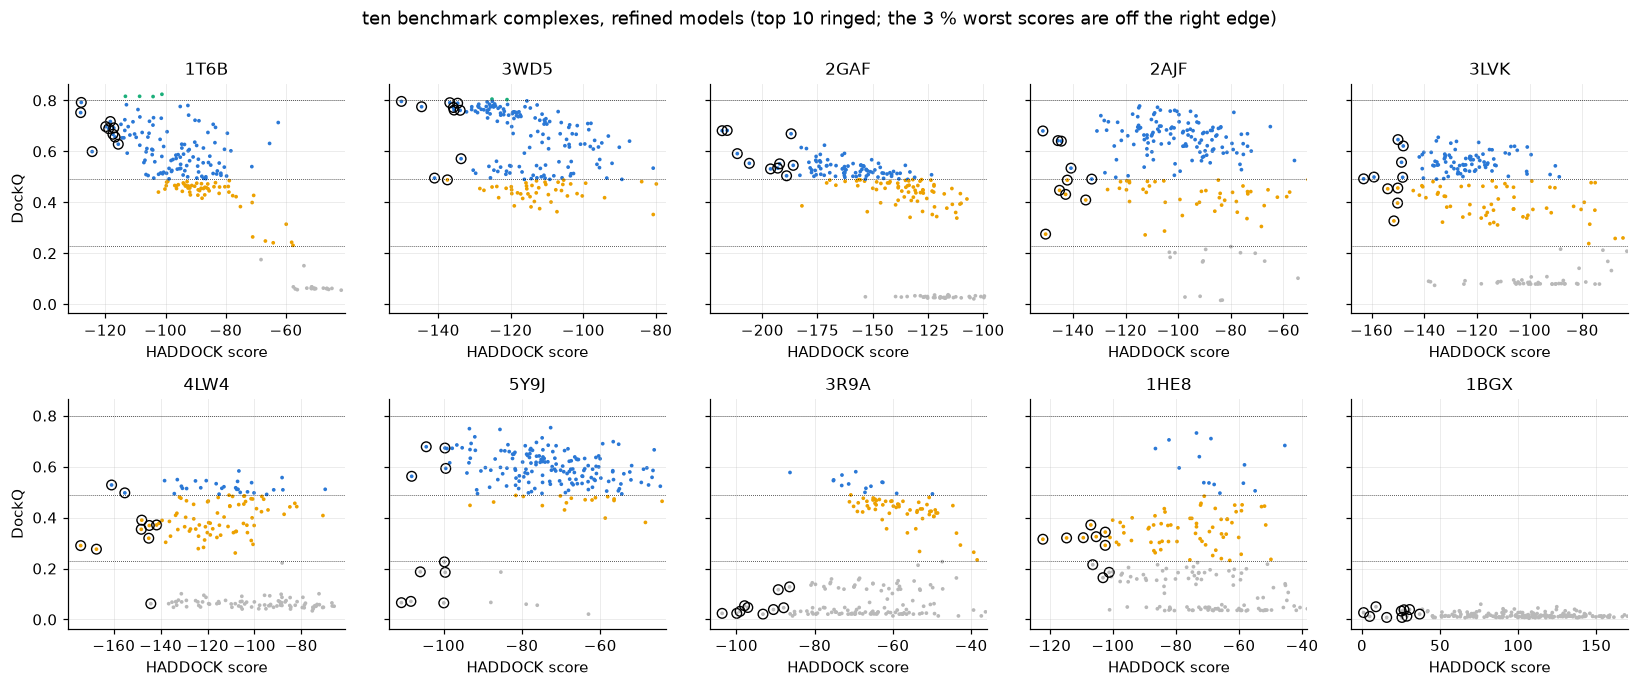

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6.2), sharey=True)
for ax, code in zip(axes.flat, COMPLEXES):
    d = BM5["refined"][code]
    cls = class_of(d["dockq"])
    ax.scatter(d["score"], d["dockq"], s=6, c=[CLASS_COLOR[c] for c in cls], lw=0)
    ax.scatter(d["score"][:10], d["dockq"][:10], s=40, facecolors="none", edgecolors="k", lw=0.9)
    for t in (0.23, 0.49, 0.80):
        ax.axhline(t, color="k", lw=0.5, ls=":")
    lo, hi = d["score"].min(), np.percentile(d["score"], 97)
    ax.set_xlim(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
    ax.set_title(code); ax.set_xlabel("HADDOCK score")
for ax in axes[:, 0]:
    ax.set_ylabel("DockQ")
fig.suptitle("ten benchmark complexes, refined models (top 10 ringed; the 3 % worst scores are off the right edge)", y=1.0)
plt.tight_layout(); plt.show()

In [13]:
for stage in ("rigid", "refined"):
    print_benchmark([("HADDOCK score", {c: BM5[stage][c]["score"] for c in COMPLEXES})], stage,
                    f"{stage}: the HADDOCK score on the ten complexes (success rates in %)")

rigid: the HADDOCK score on the ten complexes (success rates in %)
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.271      50/80/90      0/0/20        0.44  0.41  0.34  0.20  0.40  0.20  0.43  0.11  0.17  0.02

refined: the HADDOCK score on the ten complexes (success rates in %)
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.400      70/80/80    50/70/70        0.71  0.71  0.62  0.53  0.47  0.36  0.24  0.04  0.31  0.02

**Transfer, revisited.** In part 1 the weights searched on the case-study complex helped a little in rigid body
and not at all after refinement. Do the normalised scores of §5 and the machine-learning models of §6, also
trained on the case-study complex, transfer better? The last column counts the complexes for which each function
does better, and worse, than the HADDOCK score (by more than 0.01 in $\text{RQ}_{10}$).

In [14]:
def zscored_scores(stage, weights):
    """Score every complex with `weights` applied to its z-scored terms (normalised per complex)."""
    return {c: features(BM5[stage][c]) @ np.array([weights[t] for t in TERMS]) for c in COMPLEXES}

def ml_scores(stage, method, train):
    """Train `method` on data set `train` (dict of arrays) and score every complex (minus predicted DockQ)."""
    X_train, y_train = features(train), train["dockq"]
    return {c: -predict_dockq(method, X_train, y_train, features(BM5[stage][c])) for c in COMPLEXES}


if not (ex1_ok and "BEST_WZ" in globals()):
    print("Not yet: complete Exercise 1 and run the cells of section 5 first.")
else:
    for stage, key in (("rigid", "pp_rigid"), ("refined", "pp_refined")):
        rows = [("HADDOCK score", {c: BM5[stage][c]["score"] for c in COMPLEXES}),
                ("random search (sec. 4)", {c: haddock_score(BM5[stage][c], BEST_W[key]) for c in COMPLEXES}),
                ("z-scored search (sec. 5)", zscored_scores(stage, BEST_WZ[key])),
                ("z-scored, all weights equal", zscored_scores(stage, EQUAL)),
                ("linear regression (sec. 6)", ml_scores(stage, "linear regression", DATA[key])),
                ("random forest (sec. 6)", ml_scores(stage, "random forest", DATA[key]))]
        print_benchmark(rows, stage, f"{stage}: scoring functions tuned on the case-study complex")

rigid: scoring functions tuned on the case-study complex
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.271      50/80/90      0/0/20        0.44  0.41  0.34  0.20  0.40  0.20  0.43  0.11  0.17  0.02
random search (sec. 4)              0.297      60/90/90    10/40/60        0.37  0.48  0.37  0.23  0.45  0.26  0.31  0.13  0.35  0.02   better 7, worse 2
z-scored search (sec. 5)            0.283      50/80/90    10/20/50        0.34  0.62  0.36  0.18  0.39  0.21  0.29  0.10  0.33  0.02   better 4, worse 4
z-scored, all weights equal         0.228      50/50/90      0/0/10        0.44  0.41  0.35  0.17  0.39  0.09  0.06  0.06  0.29  0.01   better 2, worse 4
linear regression (sec. 6)          0.303      60/70/80    10/20/30        0.60  0.48  0.44  0.39  0.40  0.11  0.47  0.06  0.07  0.01   better 5, worse 3
random forest (sec. 6)              0.311      60/70/80    10/20/20        0.27  0.65  0.42  0.42  0.29  0.42  0.48  0.05  0.09  0.01   better 5, worse 4

refined: scoring functions tuned on the case-study complex
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.400      70/80/80    50/70/70        0.71  0.71  0.62  0.53  0.47  0.36  0.24  0.04  0.31  0.02
random search (sec. 4)              0.403      60/80/80    40/70/70        0.72  0.74  0.62  0.46  0.48  0.38  0.33  0.05  0.22  0.03   better 4, worse 2
z-scored search (sec. 5)            0.401      60/80/80    40/70/70        0.72  0.66  0.62  0.43  0.46  0.39  0.37  0.06  0.26  0.03   better 3, worse 4
z-scored, all weights equal         0.419      80/80/80    50/70/70        0.72  0.74  0.63  0.53  0.42  0.34  0.49  0.03  0.27  0.02   better 2, worse 3
linear regression (sec. 6)          0.379      80/80/90    40/70/80        0.72  0.45  0.41  0.37  0.47  0.38  0.65  0.06  0.25  0.03   better 3, worse 4
random forest (sec. 6)              0.442      80/80/80    50/70/70        0.74  0.74  0.56  0.49  0.43  0.41  0.65  0.03  0.33  0.03   better 5, worse 3

**Optimise on many complexes.** Finally, the proper procedure: tune on **several complexes at once** and test
on a complex that was **not** used. With ten complexes, the most data-efficient way is **leave one complex
out**: tune on nine, test on the tenth, and repeat for each of the ten. Four methods are tuned this way:

* the random search of §4 (raw terms, starting from the HADDOCK weights), now maximising the **mean**
  $\text{RQ}_{10}$ over the training complexes;
* the same search on terms **z-scored per complex** (starting from equal weights). Unlike in §5, this is
  *not* the same as using raw terms: each complex has its own means and standard deviations, so the
  normalisation now changes which weights work for all complexes at once;
* linear regression and the random forest of §6, trained on the models of the nine training complexes.

For comparison, the first search is also run **in-sample**, on all ten complexes, and tested on the same ten.
This takes a minute or two (longer in the browser).

rigid: tuned on nine complexes, tested on the tenth
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.271      50/80/90      0/0/20        0.44  0.41  0.34  0.20  0.40  0.20  0.43  0.11  0.17  0.02
search, raw terms (left out)        0.314      60/90/90     0/40/50        0.42  0.41  0.37  0.30  0.47  0.30  0.29  0.29  0.26  0.02   better 6, worse 2
search, z-scored terms (left out)   0.289      70/90/90     0/30/40        0.42  0.44  0.36  0.28  0.26  0.27  0.28  0.25  0.32  0.02   better 6, worse 3
linear regression (left out)        0.341      70/90/90    20/20/30        0.60  0.62  0.29  0.40  0.40  0.32  0.41  0.23  0.12  0.01   better 5, worse 3
random forest (left out)            0.284      70/80/90    20/20/40        0.10  0.65  0.09  0.32  0.22  0.42  0.52  0.31  0.19  0.02   better 6, worse 3
search on all ten (in-sample)       0.350      70/90/90    20/50/50        0.42  0.41  0.37  0.30  0.49  0.30  0.29  0.27  0.63  0.02   better 6, worse 2

   weights of the raw-term search, one set per left-out complex (median and range):
          vdw: median 0.000499   range        0 to  0.00324   (HADDOCK 0.01)
         elec: median        0   range        0 to    0.568   (HADDOCK 1)
       desolv: median     1.43   range    0.236 to     2.99   (HADDOCK 1)
          air: median     0.13   range   0.0265 to    0.284   (HADDOCK 0.01)
          bsa: median -0.00214   range -0.00823 to -0.000739   (HADDOCK -0.01)



refined: tuned on nine complexes, tested on the tenth
                                     mean   success rate (%) in top 1/5/10    RQ10 per complex
                                     RQ10    acceptable      medium        1T6B  3WD5  2GAF  2AJF  3LVK  4LW4  5Y9J  3R9A  1HE8  1BGX   vs HADDOCK (|diff| > 0.01)
HADDOCK score                       0.400      70/80/80    50/70/70        0.71  0.71  0.62  0.53  0.47  0.36  0.24  0.04  0.31  0.02
search, raw terms (left out)        0.421      80/90/90    40/80/80        0.53  0.69  0.58  0.60  0.47  0.35  0.66  0.10  0.20  0.03   better 3, worse 4
search, z-scored terms (left out)   0.405      70/80/90    40/70/80        0.53  0.50  0.62  0.60  0.44  0.35  0.62  0.28  0.08  0.03   better 3, worse 4
linear regression (left out)        0.397      70/70/80    50/70/70        0.54  0.51  0.63  0.58  0.53  0.38  0.60  0.05  0.11  0.03   better 6, worse 3
random forest (left out)            0.383      70/70/80    40/60/70        0.53  0.66  0.50  0.62  0.37  0.33  0.62  0.09  0.09  0.02   better 3, worse 6
search on all ten (in-sample)       0.489      80/90/90    70/80/90        0.70  0.69  0.61  0.61  0.52  0.41  0.65  0.37  0.30  0.03   better 5, worse 2

   weights of the raw-term search, one set per left-out complex (median and range):
          vdw: median    0.113   range        0 to     2.83   (HADDOCK 1)
         elec: median    0.305   range   0.0127 to     0.54   (HADDOCK 0.2)
       desolv: median     2.12   range   0.0697 to     5.57   (HADDOCK 1)
          air: median     1.47   range    0.154 to     3.06   (HADDOCK 0.1)
          bsa: median -0.000734   range  -0.0235 to        0   (HADDOCK 0)



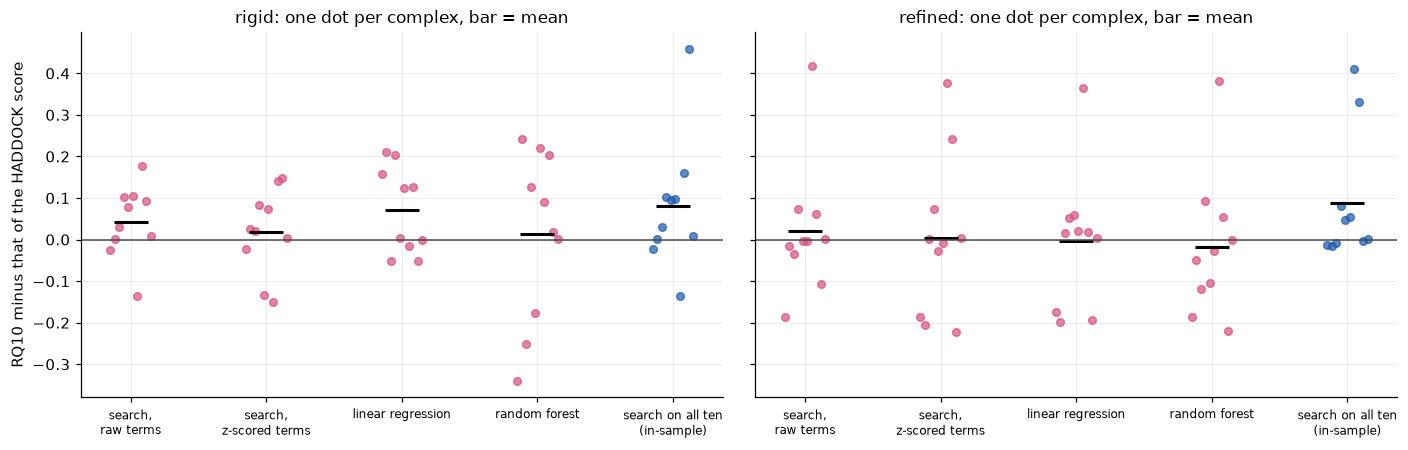

In [15]:
def search_many(sets, start, zscored, n_trials=4000, seed=1, n=10):
    """random_search (part 1, section 9) on several complexes at once: maximise the mean RQ_n over `sets`."""
    rng = np.random.default_rng(seed)
    w0 = np.array([start[t] for t in TERMS], dtype=float)
    sign = np.array([1, 1, 1, 1, -1.0])
    scale = np.where(w0 != 0, w0, sign * 0.01 * np.abs(w0).max())
    factor = 10 ** rng.uniform(-1.5, 1.5, size=(n_trials, len(TERMS)))
    W = np.where(rng.random((n_trials, len(TERMS))) < 0.15, 0.0, scale * factor)
    W[0] = w0
    c = np.cumsum((1 / np.arange(1, n + 1))[::-1])[::-1] / n
    quality = np.zeros(n_trials)
    for d in sets:
        E = features(d) if zscored else np.column_stack([d[t] for t in TERMS])
        for i in range(0, n_trials, 2000):
            S = E @ W[i:i + 2000].T
            top = np.argpartition(S, n, axis=0)[:n]
            top = np.take_along_axis(top, np.argsort(np.take_along_axis(S, top, 0), 0), 0)
            quality[i:i + 2000] += c @ d["dockq"][top]
    best = int(np.argmax(quality))
    return dict(zip(TERMS, W[best])), quality[best] / len(sets)


def leave_one_complex_out(stage, start):
    scores = {m: {} for m in ("search, raw terms", "search, z-scored terms", "linear regression", "random forest")}
    weights = []
    for k, test in enumerate(COMPLEXES):
        train = [BM5[stage][c] for c in COMPLEXES if c != test]
        d = BM5[stage][test]
        w, _ = search_many(train, start, zscored=False, seed=k)
        weights.append(w)
        scores["search, raw terms"][test] = haddock_score(d, w)
        wz, _ = search_many(train, EQUAL, zscored=True, seed=k)
        scores["search, z-scored terms"][test] = features(d) @ np.array([wz[t] for t in TERMS])
        X_train = np.vstack([features(t) for t in train])
        y_train = np.concatenate([t["dockq"] for t in train])
        for m in ("linear regression", "random forest"):
            scores[m][test] = -predict_dockq(m, X_train, y_train, features(d))
    return scores, weights


LOCO = {}
for stage, start in (("rigid", W_RIGID), ("refined", W_REFINE)):
    scores, weights = leave_one_complex_out(stage, start)
    w_all, _ = search_many([BM5[stage][c] for c in COMPLEXES], start, zscored=False)
    rows = [("HADDOCK score", {c: BM5[stage][c]["score"] for c in COMPLEXES})]
    rows += [(f"{m} (left out)", s) for m, s in scores.items()]
    rows.append(("search on all ten (in-sample)", {c: haddock_score(BM5[stage][c], w_all) for c in COMPLEXES}))
    LOCO[stage] = rows
    print_benchmark(rows, stage, f"{stage}: tuned on nine complexes, tested on the tenth")
    print("   weights of the raw-term search, one set per left-out complex (median and range):")
    for t in TERMS:
        v = np.array([w[t] for w in weights])
        print(f"      {t:>7}: median {np.median(v):8.3g}   range {v.min():8.3g} to {v.max():8.3g}"
              f"   (HADDOCK {start[t]:g})")
    print()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, stage in zip(axes, ("rigid", "refined")):
    rows = LOCO[stage]
    ref = benchmark_summary(rows[0][1], stage)[2]
    for i, (label, sc) in enumerate(rows[1:]):
        rq = benchmark_summary(sc, stage)[2]
        ax.plot(np.full(len(rq), i) + np.linspace(-0.15, 0.15, len(rq)), rq - ref, "o", ms=5,
                color=C_YOU if "in-sample" not in label else C_REF, alpha=0.7)
        ax.plot(i, np.mean(rq - ref), "_", color="k", ms=22, mew=2)
    ax.axhline(0, color=C_HADDOCK, lw=1)
    ax.set_xticks(range(len(rows) - 1))
    ax.set_xticklabels([l.replace(" (left out)", "").replace(" (in-sample)", "\n(in-sample)")
                        .replace(", ", ",\n") for l, _ in rows[1:]], fontsize=8)
    ax.set_title(f"{stage}: one dot per complex, bar = mean")
axes[0].set_ylabel("RQ10 minus that of the HADDOCK score")
plt.tight_layout(); plt.show()

**Questions**

**(a)** Do the normalised scores and the machine-learning models trained on the case-study complex transfer
better than the searched weights did in part 1?

**(b)** With leave-one-complex-out, is any method clearly better than the HADDOCK score? Look at the mean, but
also at the spread over complexes in the figure. How much better does the in-sample search look, and why?

**(c)** Which weight does the search increase most? Why would that work *here*, and would it in a real docking
run? *(Hint: where do the restraints of these runs come from?)*

**(d)** Does normalising per complex help when one set of weights must work for all complexes?

**(e)** What would you need to show that a new scoring function — a weighted sum or a machine-learning model —
is really better than HADDOCK's?

<details open>
<summary><b>Section 7 — answers</b></summary>

**(a)** No better, and no worse in general — erratic. **Rigid body:** searched weights 0.297 (better for 7
complexes, worse for 2), z-scored search 0.283 (4 and 4), equal z-weights 0.228 (2 and 4), linear regression
0.303 (5 and 3), random forest 0.311 (5 and 4), against HADDOCK's 0.271; the machine-learning models swing widely
from complex to complex (the forest: 1T6B 0.44 → 0.27, 4LW4 0.20 → 0.42). **Refined:** searched 0.403, z-scored
0.401, equal z 0.419, linear 0.379, forest 0.442, against 0.400 — each better for some complexes and worse for
others. The best means (forest, equal z) owe most of their advantage to a single complex, 5Y9J (0.24 → 0.65 and
0.49).

**(b)** **Rigid body:** a modest but fairly consistent gain for the raw-term search (0.314; better for 6, worse
for 2) and the linear regression (0.341; 5 and 3); the random forest's mean (0.28) hides losses of up to −0.34
(1T6B). **Refined:** no method is reliably better: the means stay within ±0.02 of HADDOCK's 0.400 (raw search
0.421, z-scored 0.405, linear 0.397, forest 0.383), while single complexes swing by ±0.2–0.4. The in-sample
search looks much better (0.350 rigid, 0.489 refined): even with ten complexes, tuning and testing on the same
complexes overestimates the gain, by +0.04 and +0.07 here.

**(c)** The **restraint** weight: in rigid body the median $w_\text{AIR}$ of the searches is 0.13 (13 × HADDOCK's
0.01) and electrostatics is switched off (median $w_\text{elec}$ = 0); after refinement $w_\text{AIR}$ goes from 0.1 to a
median of 1.5. That works here because the restraints were taken from the **true interface**: satisfying them
*is* being right. In a real docking run restraints come from mutagenesis, NMR, cross-links or predictions, and
are incomplete or partly wrong; a score that trusts them blindly ranks first the models that satisfy wrong
restraints. The conditions under which a scoring function is tuned must be the conditions under which it will
be used.

**(d)** Not here: the search on per-complex z-scores (0.289 rigid, 0.405 refined) does no better than the search
on raw terms (0.314, 0.421). Per-complex normalisation does make the terms of different complexes comparable —
the restraint energy of 1BGX reaches thousands of kcal/mol — but it also throws away information: a model that is
bad on an absolute scale can still get a good z-score if all the models of its complex are bad.

**(e)** Many complexes — hundreds, of different types and difficulty — docked under realistic conditions
(several restraint scenarios, including noisy and ab initio ones); validation by leaving out **whole complexes**,
never just models; a final test set that is not used for any choice; success rates with **error bars** (with ten
complexes, one complex is 10 % of the success rate); and an improvement that is consistent across complexes, not
driven by one or two. Machine-learning scoring functions that do work are trained in exactly that way, and
usually on much richer, atom-level descriptions of the interface than five numbers.
</details>

---
## **8. Take-home messages**

* **Normalising does not create information.** z-scoring is a linear rescaling: within one set of models it
  cannot find a better ranking, but it makes weights comparable (it shows which terms really drive a score) and
  gives a reasonable parameter-free baseline. It also makes the score relative to the set of models.
* **More flexible models need more data.** A random forest or nearest-neighbour model trained on one complex
  learns *that complex*: which corner of term space its correct pose occupies. Tested on new models of the
  same complex it can look spectacular; on other complexes it is erratic — large gains for some, large losses
  for others — and not reliably better than the five-weight HADDOCK score. Regressors trained to predict DockQ
  everywhere also optimise the wrong thing: what matters is the ranking at the top.
* **Optimise on many complexes, test on others.** Tuned on nine complexes and tested on the tenth, the gains are
  modest in rigid body and absent after refinement, and the in-sample result overestimates them — even with ten
  complexes, which are still very few. A scoring function must be optimised on a **large and diverse set of
  complexes** (the docking benchmark has more than 200), validated on complexes left out of the optimisation.
* **Tune under the conditions of use.** With restraints from the true interface, every optimisation learns to
  trust the restraint energy — a lesson that would be wrong in a real docking run. That is how HADDOCK's weights
  were obtained — on large benchmarks, under realistic conditions — and why they are hard to beat.

## **Going further**

Open-ended, no scaffolding provided:

* **Rank normalisation.** Replace each term by its rank (`avg_ranks`) instead of its z-score. This is not a
  linear rescaling: can it find rankings the raw terms cannot? Does the gain survive cross-validation?
* **Robust normalisation.** Use the median and inter-quartile range instead of mean and standard deviation.
  Does it change the results of §7, where the restraint energy of some complexes has huge outliers?
* **Learning to rank.** Instead of predicting DockQ, train a model to order pairs of models correctly, or
  optimise $\text{RQ}_{10}$ directly (as the random search does for a weighted sum). Does the random forest improve?
* **Classify instead of regress.** Train a classifier for "medium quality or better" and rank by its predicted
  probability.
* **Train on the benchmark, test on the case study.** Tune the weights on the ten complexes of §7 and apply them
  to the case-study complex. Does it beat the HADDOCK score there?